# Playing styles inside each role

A fullback who crosses and a fullback who tackles are both fullbacks. This notebook splits each role on those actions, using 2025-26 players with at least 900 minutes. Goalkeepers are already out of the file.

The style names are proposals. They live in `data/processed/cluster_names.csv`, which is the file to edit by hand. The player assignments keep a name once it has been changed there.

## Why the first version failed: clustering on outcomes vs. actions

The first fit included goals, assists, and goals per shot. Those are results, so every role split into players who scored and players who did not. João Palhinha was labeled a goalscoring midfielder because he scored more than a typical midfielder, even though his actions are tackles and interceptions. Pedro Porro was labeled a holding fullback because he barely scored, even though he gets up the pitch to cross and shoot.

The fit below drops those outcome columns. Palhinha comes out as a ball-winning destroyer. Porro comes out as an attacking wing-back.

## How a style is chosen

Styles use actions only: shots, shot accuracy, crosses, tackles won, interceptions, fouls committed, fouls drawn, and offsides. Inside a role, if two of those columns correlate above 0.8, one is dropped, because it repeats the same action. Shots on target per 90 is the column that usually goes, since shot volume and shot accuracy are already there. The columns that remain are z-scored again inside that role.

For each role we fit three clusters and four. The notebook shows silhouette, the stability check, and the cluster sizes for both. A cluster under 10% of the role is too small to treat as a style. When both splits pass that test, we keep the one that separates more styles which are each high on their own action. If one split reshuffles across seeds and the other does not, we keep the stable one. The sentence under each table is the reason for that role.

The scatter is a flat view of those same action stats. The axis label is the share of the spread that direction captures. Tottenham players are ringed and named.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cluster import cluster_playing_styles

LABELS = {
    "goals_per90": "Goals per 90",
    "non_penalty_goals_per90": "Non-penalty goals per 90",
    "assists_per90": "Assists per 90",
    "shots_per90": "Shots per 90",
    "shots_on_target_per90": "Shots on target per 90",
    "crosses_per90": "Crosses per 90",
    "tackles_won_per90": "Tackles won per 90",
    "interceptions_per90": "Interceptions per 90",
    "fouls_committed_per90": "Fouls committed per 90",
    "fouls_drawn_per90": "Fouls drawn per 90",
    "offsides_per90": "Offsides per 90",
    "shot_accuracy": "Shot accuracy",
    "goals_per_shot": "Goals per shot",
}
ROLE_ORDER = ["CB", "FB", "CM", "AM_W", "ST"]
ROLE_TITLE = {
    "CB": "Centre-backs",
    "FB": "Fullbacks",
    "CM": "Central midfielders",
    "AM_W": "Attacking midfielders and wingers",
    "ST": "Strikers",
}
COLORS = ["#132257", "#C4A35A", "#2F6F4E", "#8C4A3A", "#4C6CB3"]

result = cluster_playing_styles()
players = result["players"]
names = result["names"]
diagnostics = result["diagnostics"]
features = result["features"]

def feature_phrase(pairs_text):
    parts = []
    for piece in pairs_text.split(", "):
        feature, value = piece.rsplit(" ", 1)
        parts.append(f"{LABELS.get(feature, feature)} {value}")
    return ", ".join(parts)

def show_role(position_group):
    info = diagnostics[position_group]
    subset = players.loc[players["position_group"] == position_group].reset_index(drop=True)
    coords = info["pca"]["coords"]
    subset = subset.copy()
    subset["pc1"] = coords[:, 0]
    subset["pc2"] = coords[:, 1]
    role_names = names.loc[names["position_group"] == position_group].sort_values("cluster_id")

    comparison = pd.DataFrame(info["comparison"])
    comparison["sizes"] = comparison["sizes"].map(lambda sizes: ", ".join(str(size) for size in sizes))
    comparison["silhouette"] = comparison["silhouette"].round(3)
    comparison["ARI"] = comparison["mean_ari"].round(3)
    print(ROLE_TITLE[position_group])
    display(comparison[["k", "silhouette", "ARI", "sizes"]])
    state = "stable" if info["stability"]["stable"] else "unstable"
    print(
        f"Chosen k = {info['k']} (silhouette {info['silhouette']:.3f}, "
        f"ARI {info['stability']['mean_ari']:.3f}, {state})."
    )
    print(info["reason"])

    variance = info["pca"]["explained_variance_ratio"]
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for cluster_id, colour in zip(role_names["cluster_id"], COLORS):
        chunk = subset.loc[subset["cluster_id"] == cluster_id]
        label = role_names.loc[role_names["cluster_id"] == cluster_id, "cluster_name"].iloc[0]
        others = chunk.loc[chunk["team"] != "Tottenham"]
        ax.scatter(others["pc1"], others["pc2"], s=18, alpha=0.75, color=colour, label=label)
    spurs = subset.loc[subset["team"] == "Tottenham"]
    ax.scatter(
        spurs["pc1"],
        spurs["pc2"],
        s=70,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
        zorder=4,
        label="Tottenham",
    )
    for row in spurs.itertuples(index=False):
        ax.annotate(row.player, (row.pc1, row.pc2), fontsize=8, xytext=(5, 4), textcoords="offset points")
    ax.set_xlabel(f"PC1 ({variance[0] * 100:.0f}% of variance)")
    ax.set_ylabel(f"PC2 ({variance[1] * 100:.0f}% of variance)")
    ax.set_title(ROLE_TITLE[position_group])
    ax.legend(frameon=False, loc="best")
    fig.tight_layout()
    plt.show()

    for style in role_names.itertuples(index=False):
        members = subset.loc[subset["cluster_id"] == style.cluster_id]
        typical = members.nsmallest(3, "distance_to_centroid")
        spurs_here = members.loc[members["team"] == "Tottenham", "player"].tolist()
        table = pd.DataFrame(
            {
                "Style": [style.cluster_name],
                "Players": [int(style.size)],
                "High": [feature_phrase(style.high_features)],
                "Low": [feature_phrase(style.low_features)],
                "Most typical": [", ".join(typical["player"].tolist())],
                "Spurs": [", ".join(spurs_here) if spurs_here else "none"],
            }
        )
        display(table)


AM_W: drop shots_on_target_per90 (|r|=0.87 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.


CB: drop shots_on_target_per90 (|r|=0.82 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.


CM: drop shots_on_target_per90 (|r|=0.85 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.


ST: drop shots_on_target_per90 (|r|=0.82 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.


## Centre-backs

Centre-backs


,k,silhouette,ARI,sizes
0,3,0.161,0.966,"203, 11, 125"
1,4,0.119,0.961,"11, 108, 121, 99"


Chosen k = 3 (silhouette 0.161, ARI 0.966, stable).
Both k=3 and k=4 leave a cluster under 10% of the role (11 players, 3%). k=3 is the cleaner reading, because splitting further does not absorb that small group.


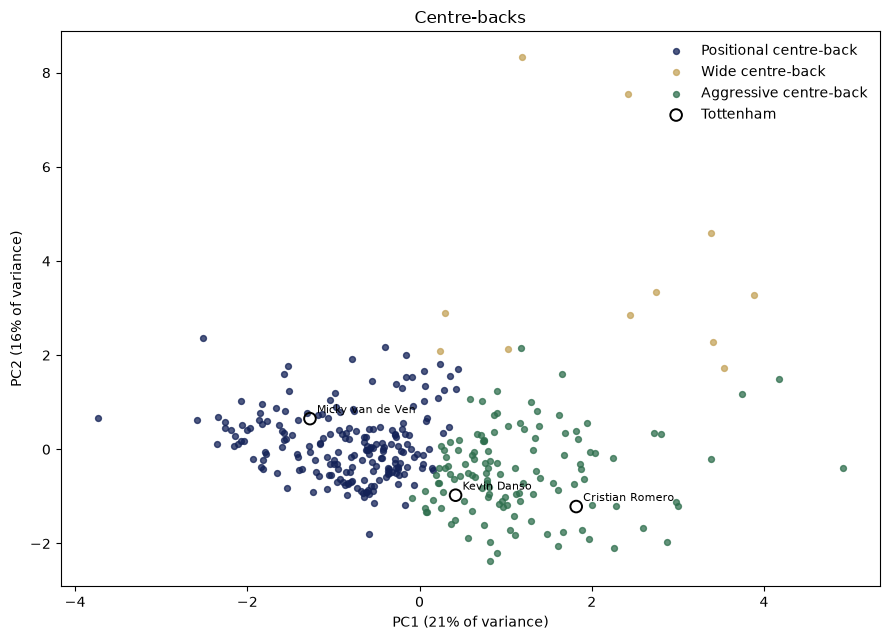

,Style,Players,High,Low,Most typical,Spurs
0,Positional centre-back,203,"Offsides per 90 (-0.09), Shot accuracy (-0.10)...","Fouls committed per 90 (-0.41), Fouls drawn pe...","Joachim Andersen, Jhon Lucumí, Ayumu Seko",Micky van de Ven


,Style,Players,High,Low,Most typical,Spurs
0,Wide centre-back,11,"Crosses per 90 (+4.43), Offsides per 90 (+1.63...","Interceptions per 90 (-0.69), Fouls drawn per ...","José Luis Gayà, Abner, Pierre Kalulu",none


,Style,Players,High,Low,Most typical,Spurs
0,Aggressive centre-back,125,"Fouls drawn per 90 (+0.66), Fouls committed pe...","Offsides per 90 (+0.01), Crosses per 90 (+0.04)","Keven Schlotterbeck, Marc Pubill, Jérémy Jacquet","Cristian Romero, Kevin Danso"


In [2]:
show_role("CB")


## Fullbacks

Fullbacks


,k,silhouette,ARI,sizes
0,3,0.124,0.908,"71, 108, 77"
1,4,0.116,0.774,"64, 77, 74, 41"


Chosen k = 3 (silhouette 0.124, ARI 0.908, stable).
k=3 comes back across seeds (ARI 0.91) and k=4 does not (ARI 0.77). Every cluster is at least 10% of the role.


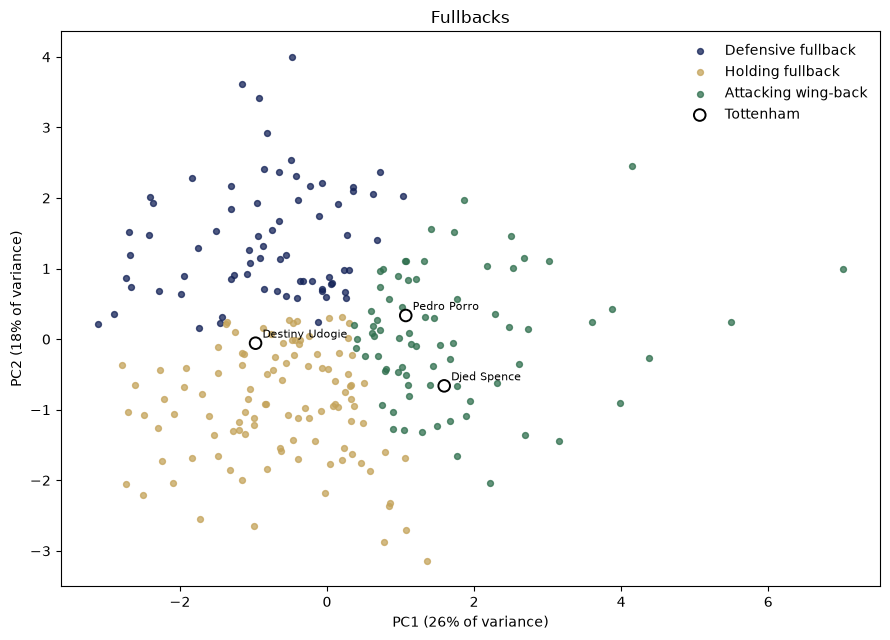

,Style,Players,High,Low,Most typical,Spurs
0,Defensive fullback,71,"Fouls committed per 90 (+0.99), Tackles won pe...","Shot accuracy (-0.57), Shots on target per 90 ...","Álex Valle, Nordi Mukiele, Lamine Sy",none


,Style,Players,High,Low,Most typical,Spurs
0,Holding fullback,108,"Crosses per 90 (-0.03), Shot accuracy (-0.07),...","Tackles won per 90 (-0.58), Fouls committed pe...","Vitaliy Mykolenko, Abel Bretones, El Hadji Mal...",Destiny Udogie


,Style,Players,High,Low,Most typical,Spurs
0,Attacking wing-back,77,"Shots on target per 90 (+1.08), Shots per 90 (...","Interceptions per 90 (-0.13), Fouls committed ...","Matty Cash, Ferdi Kadioglu, Andrei Ratiu","Djed Spence, Pedro Porro"


In [3]:
show_role("FB")


## Central midfielders

Central midfielders


,k,silhouette,ARI,sizes
0,3,0.122,0.918,"135, 158, 86"
1,4,0.128,0.936,"60, 139, 116, 64"


Chosen k = 4 (silhouette 0.128, ARI 0.936, stable).
k=4 separates more styles that are each high on their own action (3 clear profiles, versus 2 for k=3). Every cluster is at least 10% of the role.


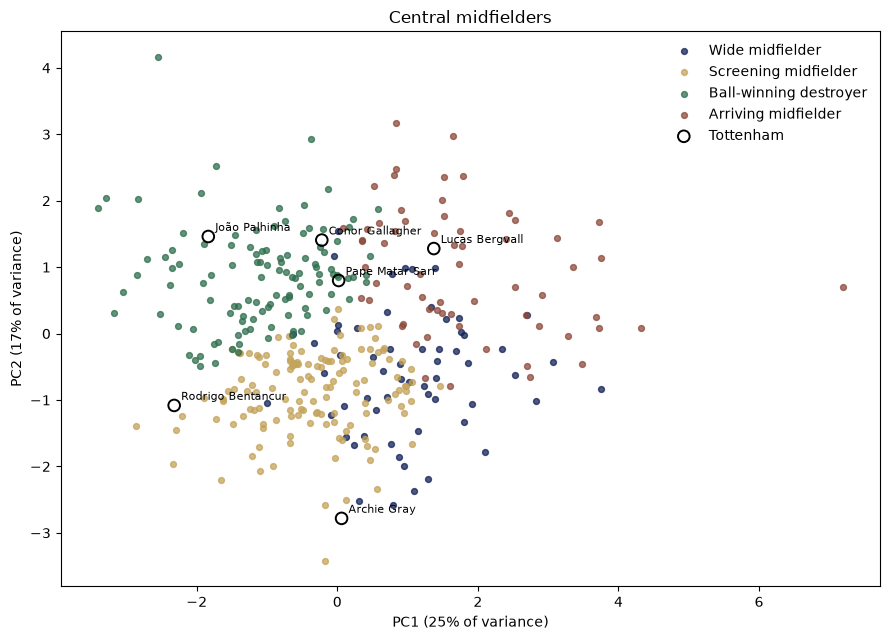

,Style,Players,High,Low,Most typical,Spurs
0,Wide midfielder,60,"Crosses per 90 (+1.76), Shots per 90 (+0.12), ...","Fouls committed per 90 (-0.64), Interceptions ...","Mathias Jensen, Sandro Tonali, Tyler Morton",none


,Style,Players,High,Low,Most typical,Spurs
0,Screening midfielder,139,"Interceptions per 90 (+0.20), Shot accuracy (+...","Fouls drawn per 90 (-0.52), Fouls committed pe...","Fran Beltrán, Laurent Abergel, Martín Zubimendi","Archie Gray, Rodrigo Bentancur"


,Style,Players,High,Low,Most typical,Spurs
0,Ball-winning destroyer,116,"Tackles won per 90 (+0.86), Fouls committed pe...","Shot accuracy (-0.52), Crosses per 90 (-0.32)","Morgan Sanson, Benjamin André, Maxence Caqueret","Conor Gallagher, João Palhinha, Pape Matar Sarr"


,Style,Players,High,Low,Most typical,Spurs
0,Arriving midfielder,64,"Shots per 90 (+1.27), Offsides per 90 (+1.14),...","Interceptions per 90 (-0.67), Tackles won per ...","Adrien Rabiot, Mauro Arambarri, Mikel Merino",Lucas Bergvall


In [4]:
show_role("CM")


## Attacking midfielders and wingers

Attacking midfielders and wingers


,k,silhouette,ARI,sizes
0,3,0.127,0.980,"98, 96, 115"
1,4,0.129,0.834,"41, 82, 75, 111"


Chosen k = 4 (silhouette 0.129, ARI 0.834, stable).
k=4 separates more styles that are each high on their own action (4 clear profiles, versus 3 for k=3). Every cluster is at least 10% of the role.


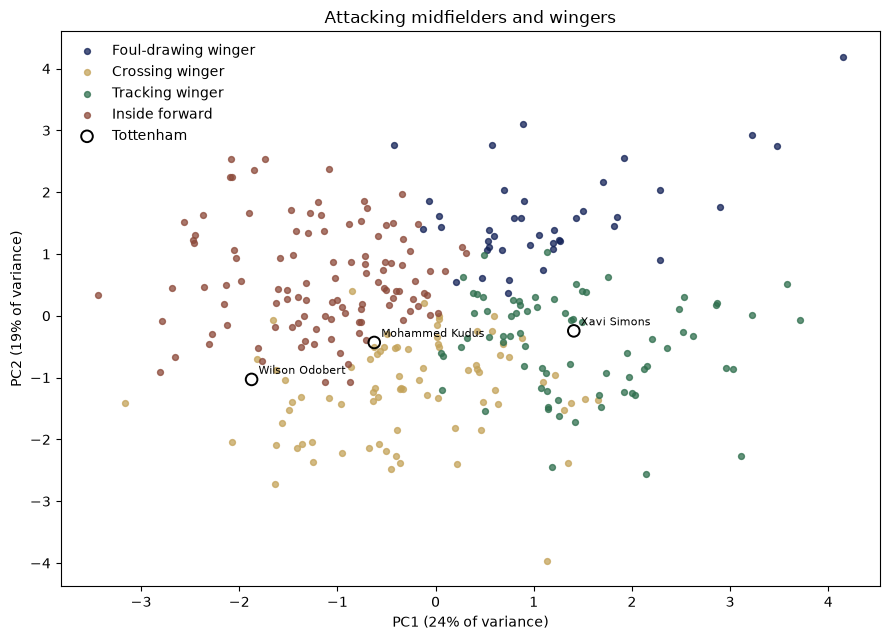

,Style,Players,High,Low,Most typical,Spurs
0,Foul-drawing winger,41,"Fouls committed per 90 (+1.29), Fouls drawn pe...","Crosses per 90 (-0.20), Shots per 90 (-0.06)","Lucas Paquetá, Brais Méndez, Crysencio Summerv...",none


,Style,Players,High,Low,Most typical,Spurs
0,Crossing winger,82,"Crosses per 90 (+1.06), Interceptions per 90 (...","Fouls drawn per 90 (-0.49), Fouls committed pe...","Romano Schmid, Noni Madueke, Ritsu Doan",Mohammed Kudus


,Style,Players,High,Low,Most typical,Spurs
0,Tracking winger,75,"Interceptions per 90 (+0.84), Tackles won per ...","Shots per 90 (-0.70), Shot accuracy (-0.58)","Nikola Vlašić, Diego López, Jean Mattéo Bahoya",Xavi Simons


,Style,Players,High,Low,Most typical,Spurs
0,Inside forward,111,"Shots per 90 (+0.78), Shot accuracy (+0.43), O...","Tackles won per 90 (-0.66), Interceptions per ...","Julio Enciso, Marius Bülter, Víctor Muñoz",Wilson Odobert


In [5]:
show_role("AM_W")


## Strikers

Strikers


,k,silhouette,ARI,sizes
0,3,0.143,0.861,"34, 95, 71"
1,4,0.142,0.768,"74, 77, 16, 33"


Chosen k = 3 (silhouette 0.143, ARI 0.861, stable).
k=4 leaves a cluster at 8% of the role, under 10%. k=3 keeps every style large enough to describe.


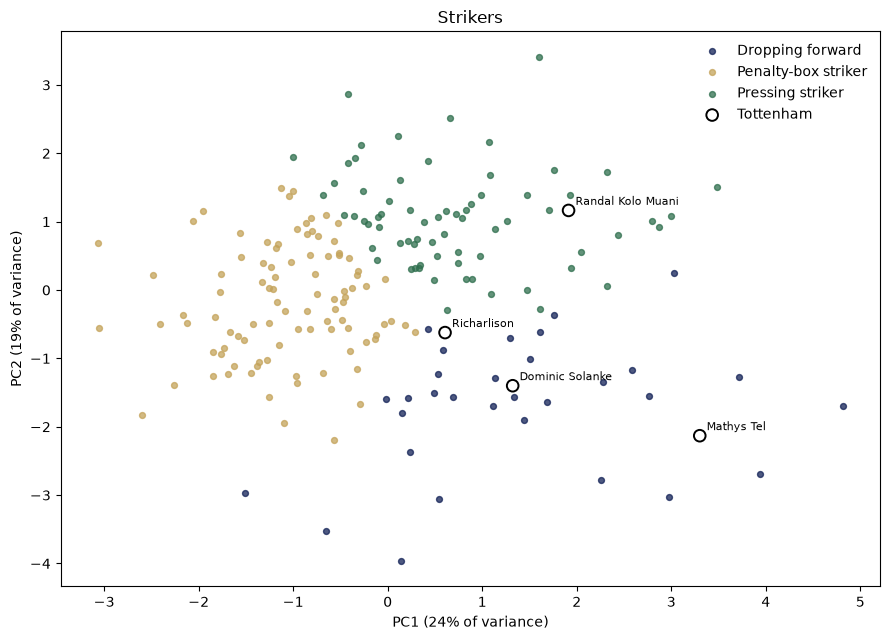

,Style,Players,High,Low,Most typical,Spurs
0,Dropping forward,34,"Crosses per 90 (+1.49), Interceptions per 90 (...","Fouls committed per 90 (-0.79), Offsides per 9...","Amine Gouiri, Matias Fernandez-Pardo, Maximili...","Dominic Solanke, Mathys Tel, Richarlison"


,Style,Players,High,Low,Most typical,Spurs
0,Penalty-box striker,95,"Shot accuracy (+0.36), Offsides per 90 (+0.24)...","Tackles won per 90 (-0.57), Fouls drawn per 90...","Ollie Watkins, Callum Wilson, Fisnik Asllani",none


,Style,Players,High,Low,Most typical,Spurs
0,Pressing striker,71,"Fouls committed per 90 (+0.87), Fouls drawn pe...","Shot accuracy (-0.46), Crosses per 90 (-0.26)","Olivier Giroud, Isaac Romero, João Pedro",Randal Kolo Muani


In [6]:
show_role("ST")


## Spurs' squad by playing style

Every Tottenham player below has at least 900 minutes in 2025-26. A style with none of them is a gap. That list is the input to the later question of which kinds of player the squad does not have.

In [7]:
spurs = players.loc[players["team"] == "Tottenham"].copy()
rows = []
for position_group in ROLE_ORDER:
    for style in names.loc[names["position_group"] == position_group].itertuples(index=False):
        members = spurs.loc[
            (spurs["position_group"] == position_group) & (spurs["cluster_id"] == style.cluster_id),
            "player",
        ].tolist()
        rows.append(
            {
                "Role": position_group,
                "Style": style.cluster_name,
                "Covered": "yes" if members else "no",
                "Spurs": ", ".join(members) if members else "none",
            }
        )
coverage = pd.DataFrame(rows)
display(coverage)
print("Styles Spurs have:")
for row in coverage.loc[coverage["Covered"] == "yes"].itertuples(index=False):
    print(f"  {row.Role} — {row.Style}: {row.Spurs}")
print("Styles Spurs do not have:")
for row in coverage.loc[coverage["Covered"] == "no"].itertuples(index=False):
    print(f"  {row.Role} — {row.Style}")


,Role,Style,Covered,Spurs
0,CB,Positional centre-back,yes,Micky van de Ven
1,CB,Wide centre-back,no,none
2,CB,Aggressive centre-back,yes,"Cristian Romero, Kevin Danso"
3,FB,Defensive fullback,no,none
4,FB,Holding fullback,yes,Destiny Udogie
5,FB,Attacking wing-back,yes,"Djed Spence, Pedro Porro"
6,CM,Wide midfielder,no,none
7,CM,Screening midfielder,yes,"Archie Gray, Rodrigo Bentancur"
8,CM,Ball-winning destroyer,yes,"Conor Gallagher, João Palhinha, Pape Matar Sarr"
9,CM,Arriving midfielder,yes,Lucas Bergvall


Styles Spurs have:
  CB — Positional centre-back: Micky van de Ven
  CB — Aggressive centre-back: Cristian Romero, Kevin Danso
  FB — Holding fullback: Destiny Udogie
  FB — Attacking wing-back: Djed Spence, Pedro Porro
  CM — Screening midfielder: Archie Gray, Rodrigo Bentancur
  CM — Ball-winning destroyer: Conor Gallagher, João Palhinha, Pape Matar Sarr
  CM — Arriving midfielder: Lucas Bergvall
  AM_W — Crossing winger: Mohammed Kudus
  AM_W — Tracking winger: Xavi Simons
  AM_W — Inside forward: Wilson Odobert
  ST — Dropping forward: Dominic Solanke, Mathys Tel, Richarlison
  ST — Pressing striker: Randal Kolo Muani
Styles Spurs do not have:
  CB — Wide centre-back
  FB — Defensive fullback
  CM — Wide midfielder
  AM_W — Foul-drawing winger
  ST — Penalty-box striker


## Limitations

Clusters only reflect the available FBref features. There is no passing, no expected goals, and no dribbling, so two players who move the ball in different ways can land in the same style if their shots, crosses, and tackles look alike.